In [1]:
#Importing libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

# ***1.0 -  Load  Data***

In [2]:
df = pd.read_csv('/content/credit_risk_dataset.csv')

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


# ***2.0 - Exploratory Data Analysis***

In [4]:
df.shape

print(f'There are {df.shape[0]} rows and, {df.shape[1]} columns')

There are 32581 rows and, 12 columns


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [6]:
print(f'Total Null values',df.isna().sum().sum())

Total Null values 4011


In [7]:
df['loan_status'].value_counts().reset_index()

,loan_status,count
0,0,25473
1,1,7108


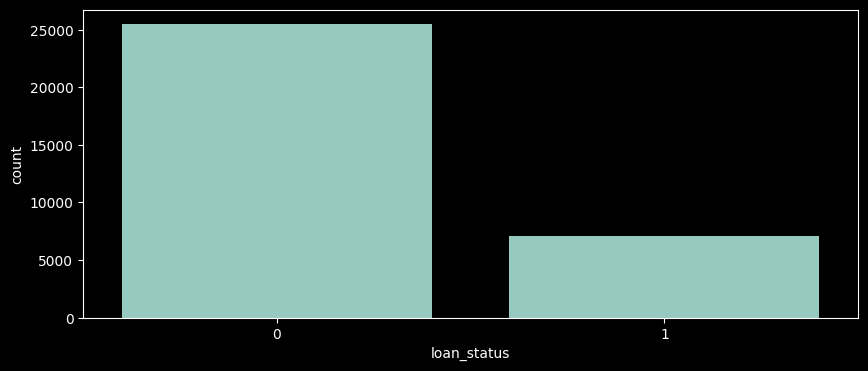

In [8]:

plt.style.use('dark_background')
plt.figure(figsize=(10,4))
sns.countplot(x='loan_status',
              data=df)
plt.show()

In [9]:
#Checking the statistical analysis

df.describe ()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [10]:
print('Person Age abv hundred - ',(df['person_age'] > 100).sum())

Person Age abv hundred -  5





* ***There are 5 people in the dataset whose age is greater than 100, which may
indicate unusually old records or potential data-entry errors worth reviewing.***





In [11]:
print('Employee length which is abv sixten - ',(df['person_emp_length'] > 60).sum())

Employee length which is abv sixten -  2




* ***There are records where employment length exceeds 60 years; these values should be reviewed, as they may represent unrealistic employment durations or possible data-entry errors.***



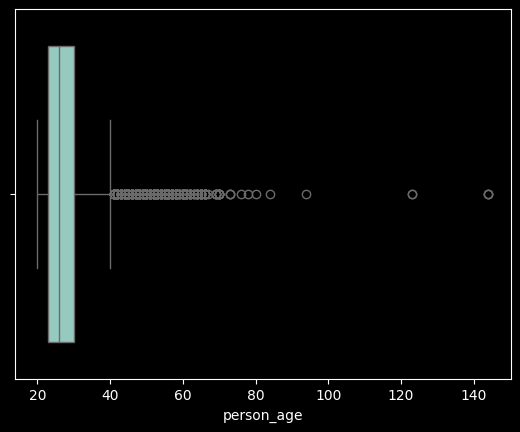

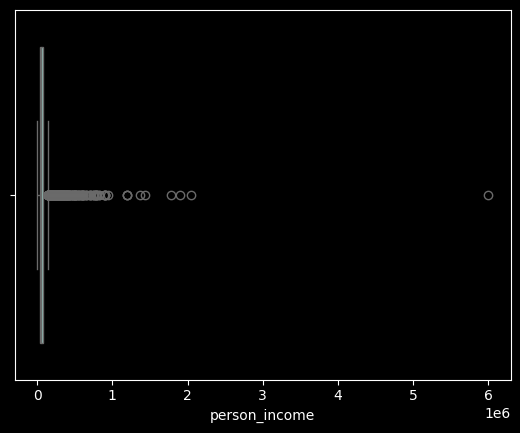

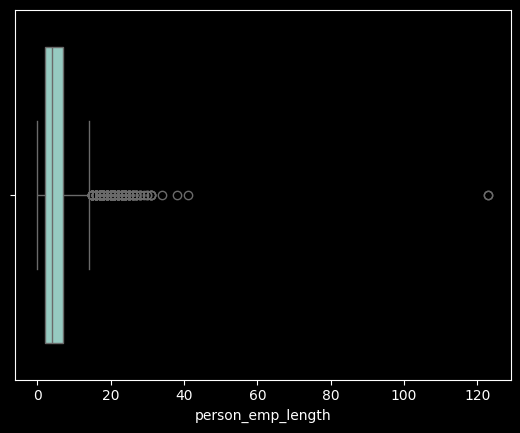

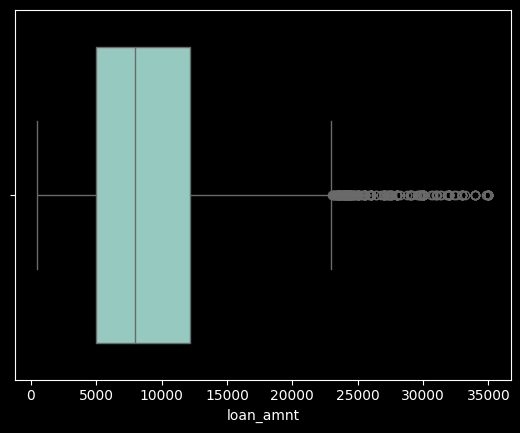

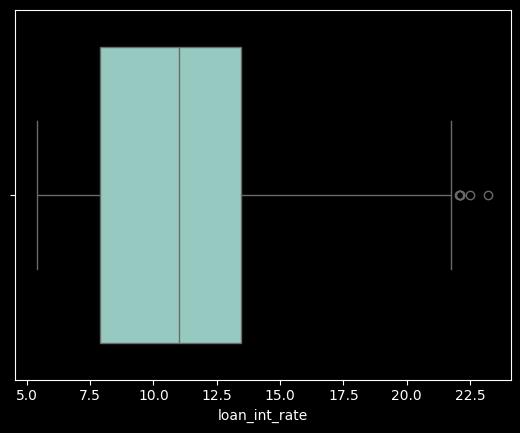

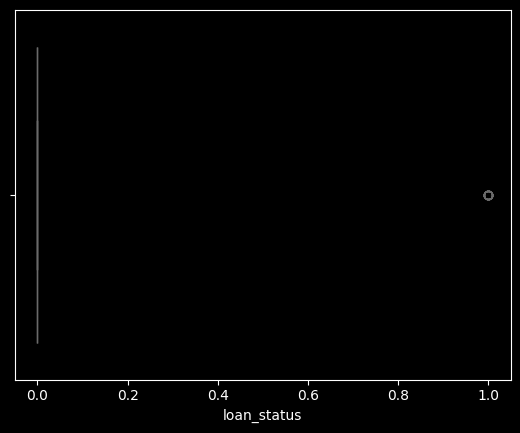

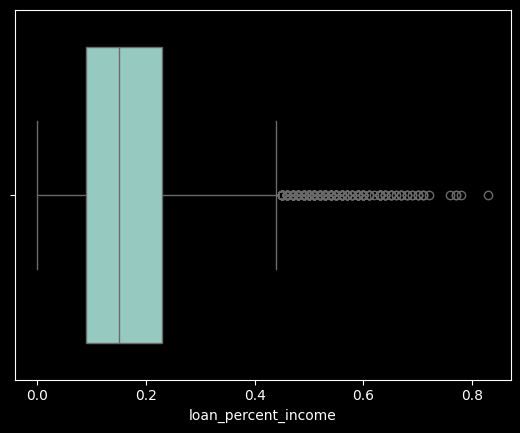

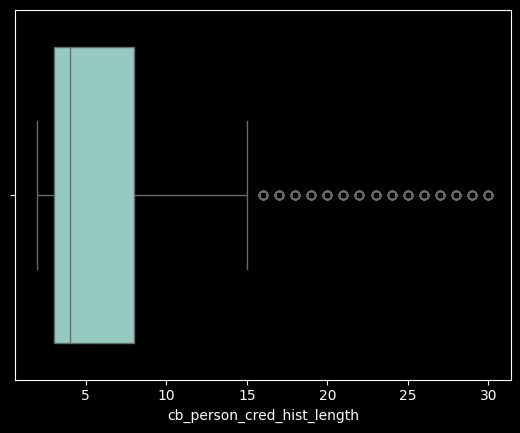

In [12]:
num_col = []

for col in df.columns:
  if df[col].dtype == 'int' or df[col].dtype == 'float':
    num_col.append(col)

for num in num_col:
  sns.boxplot(x=df[num])
  plt.show()

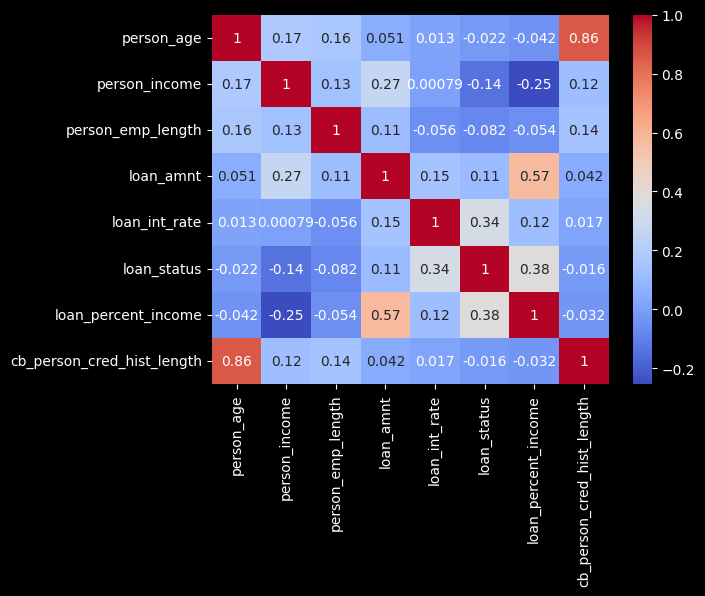

In [13]:
# Correlation.

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm')
plt.show()



*   ***person_age and cb_person_cred_hist_length have a very strong correlation (0.86). They carry similar information, so for a linear model consider keeping one or checking multicollinearity.***

*   ***loan_amnt and loan_percent_income are moderately positively correlated (0.57): larger loans generally take up more of a person’s income.***

* ***For **bold text** predicting loan_status, loan_percent_income (0.38) and loan_int_rate (0.34) show the strongest numerical relationships.***

* ***person_income and loan_percent_income have a negative correlation (-0.25): higher-income applicants tend to use a smaller share of income for the loan.***

* ***Most other relationships are weak, so there is no major concern from them.***



# ***3.0 -  Data Validation and Outlier Handling***

In [14]:
#Creating copy of Original Dataset.
df_copy = df.copy()

In [15]:
#Checing Original Rows.
print('Original Rows - ',df_copy.shape[0],'\n')

#Dropping Duplicates
#df_copy.duplicated().sum().sum()

df_copy.drop_duplicates(inplace=True)
print('Rows after removing duplicate - ',df_copy.shape[0])

Original Rows -  32581 

Rows after removing duplicate -  32416


In [16]:
#Remove rows with Impossibel age or work experience.
df_copy = df_copy[df_copy['person_age'] >= 18]
df_copy = df_copy[df_copy['person_age'] <= 100]

#Remove employee greater than age and extreme outlier(>60).
df_copy =  df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]
df_copy =  df_copy[df_copy['person_emp_length'] <= 60]

#remove the rows with zero income and load amount.
df_copy = df_copy[df_copy['loan_amnt'] > 0]

#Check if the intrest rate looks realistic.
print('Loan intrest rate range from (min: 5.42 and max: 23.22)')

Loan intrest rate range from (min: 5.42 and max: 23.22)


# ***4.0 -  Feature,  target and train test split.***

In [17]:
#Seperate the data into train and test split.

#Feature
X = df_copy.drop('loan_status', axis=1)

#Lables
y = df_copy['loan_status']

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size = 0.2,
                                                    random_state = 42,
                                                    stratify = y)


In [19]:
#Seperate out Numerical and Caterogical column to Handle Scale and Category.

numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


# ***4.1 - Handeling Class Imbalance***

In [20]:
y_train.value_counts().reset_index()

,loan_status,count
0,0,19772
1,1,5445


In [21]:
#Calculating class weight for prioritising minority classes.

neg, pos = np.bincount(y_train)
scale_weight = neg/pos
print('Class Weights', scale_weight)

Class Weights 3.6312213039485766


# ***4.2 - Preprocessing for  Logistic Regression***

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers=[
        #PIpeline for numerical column
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),

         # piepline for categorica column
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

In [23]:
preprocessor_random_forest = ColumnTransformer(
    transformers=[
        #Pipeline for numerical column.
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric_cols),

        #Pipeline for categorical column.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

# ***4.3 - Preprocessing for XGBoost***

In [24]:
preprocessor_xgboost = ColumnTransformer(
    transformers=[
        #Pipeline for numerical column
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric_cols),

         # piepline for categorica column
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

#  ***5.0 Evaluation Helper Function***

In [25]:
from sklearn.metrics import *

def Evaluate_model(model_name, model, X_test, y_test, threshold=None):

  y_pred_prob = model.predict_proba(X_test)[:,1]

  if threshold:
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(X_test)


  #Metrics
  acc_score = accuracy_score(y_test, y_pred) #Model Overall peformace.
  pre_score = precision_score(y_test, y_pred) #Of the one i picked, How many were actually correct.
  re_score  = recall_score(y_test, y_pred) #Out of everything that was really there, Much did you manage to find
  f1        = f1_score(y_test, y_pred) #Harmonic mean of precision and recall

  #Confusion metrics
  cm_metrics   = confusion_matrix(y_test, y_pred)
  class_report = classification_report(y_test, y_pred)

  print(f"{model_name} Metrics")
  print(f"Best Threshold {threshold}")
  print(f"Accuracy  : {acc_score :.2f}")
  print(f"Precision : {pre_score :.2f}")
  print(f"Recall    : {re_score :.2f}")
  print(f"F1        : {f1 :.2f}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)

  #Plotting Confusin metrics
  sns.heatmap(cm_metrics, annot=True, fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.ylabel("Actual Values")
  plt.xlabel("Predicted Values")

  plt.show()

  #Plotting ROC_AUC score
  precision, recall, threshold = precision_recall_curve(y_test,y_pred_prob)
  plt.plot(recall, precision)
  plt.ylabel("Precision")
  plt. title(f"{model_name} Precision-Recall Curve")

  plt. show()


# ***6.0 - Stratified Cross Validation***


##### ***The dataset is divided into K parts the model trains on K − 1 parts and tests on the remaining part. This repeats K times, so every part is used as the test set once. Then, average all K scores to measure performance.***

In [26]:
#Importing Libraries.

from sklearn.model_selection import StratifiedKFold, cross_validate

#Cross Validation.
cv = StratifiedKFold(n_splits=5,
                shuffle=True,
                random_state=42)

#Scoring
Scoring = {'roc_auc'   : 'roc_auc',
           'accuracy'  :  'accuracy',
           'precision' : 'precision',
           'recall'    : 'recall',
           'f1'        : 'f1'}

In [27]:
#Logistic regression

from sklearn.linear_model import LogisticRegression

lr_cv_pipeline = Pipeline([('preprocessor', preprocessor_lr),
                            ('classifier', LogisticRegression(max_iter = 1000,
                                            class_weight               = 'balanced',
                                              random_state             = 42))])
lr_cv_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

In [28]:
#Random forest

from sklearn.ensemble import  RandomForestClassifier

rf_cv_pipeline = Pipeline([('preprocessor', preprocessor_random_forest),
                           ('classifier', RandomForestClassifier(
                               n_estimators = 200,
                               criterion = 'gini',
                               min_samples_split = 4,
                               max_depth = 50,
                               random_state = 42
))])

rf_cv_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

In [29]:
#XGboost

from xgboost import XGBClassifier

xgb_cv_pipeline = Pipeline([('preprocessor', preprocessor_xgboost),
          ('classifier', XGBClassifier(
                                       n_estimators     = 300,
                                       max_depth        = 5,
                                       learning_rate    = 0.1,
                                       scale_pos_weight = scale_weight,
                                       random_state     = 42
                                      ))])

xgb_cv_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

In [30]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),('XGBoost', xgb_cv_pipeline)]:
  cv_result = cross_validate(pipe, X_train, y_train, cv = cv , scoring = Scoring)

  print(cv_name)
  print(f"ROC-AUC    : {cv_result['test_roc_auc'].mean():.2f}")
  print(f"Accuracy   : {cv_result['test_accuracy' ].mean():.2f}")
  print(f"Precision  : {cv_result['test_precision'].mean():.2f}")
  print(f"Recall     : {cv_result['test_recall'].mean():.2f}")
  print(f"F1         : {cv_result['test_f1'].mean():.2f}\n")

Logistic Regression
ROC-AUC    : 0.87
Accuracy   : 0.81
Precision  : 0.54
Recall     : 0.78
F1         : 0.64

XGBoost
ROC-AUC    : 0.95
Accuracy   : 0.92
Precision  : 0.82
Recall     : 0.80
F1         : 0.81



# ***7.0 - Baseline model Logistic Regression***

In [31]:
baseline_model = Pipeline([('Preprocessor' , preprocessor_lr),
                          ('classifier', LogisticRegression(
                                        class_weight="balanced"))])

In [32]:
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

Baseline model Logistic Regression Metrics
Best Threshold None
Accuracy  : 0.82
Precision : 0.56
Recall    : 0.79
F1        : 0.65

Baseline model Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



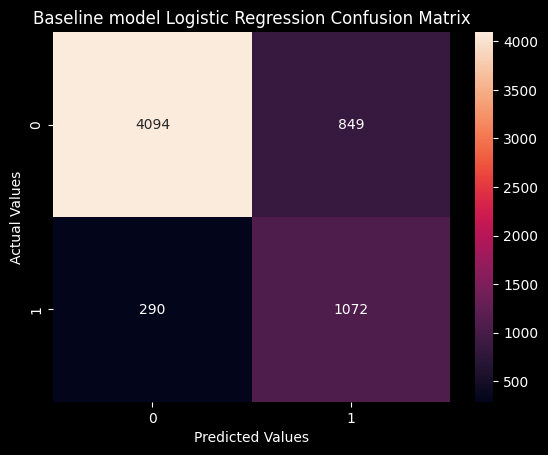

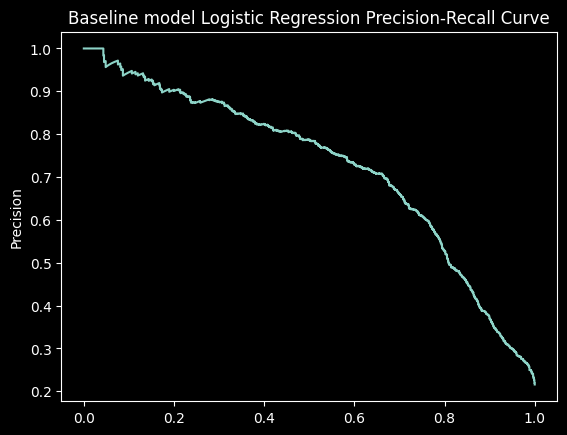

In [33]:
#Evaluating Baseline model.
Evaluate_model("Baseline model Logistic Regression",
               baseline_model, X_test, y_test)

# ***Random Forest Model***

In [34]:
rf_model = Pipeline([
                    ('Preprocessor' , preprocessor_random_forest),
                    ('classifier' , RandomForestClassifier
                                          (class_weight="balanced",
                                           random_state = 42,
                                           n_jobs = -1,
                                           max_features = 'sqrt'))])

In [35]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

RadomForest Model Metrics
Best Threshold None
Accuracy  : 0.93
Precision : 0.91
Recall    : 0.75
F1        : 0.82

RadomForest Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.96      4943
           1       0.91      0.75      0.82      1362

    accuracy                           0.93      6305
   macro avg       0.92      0.86      0.89      6305
weighted avg       0.93      0.93      0.93      6305



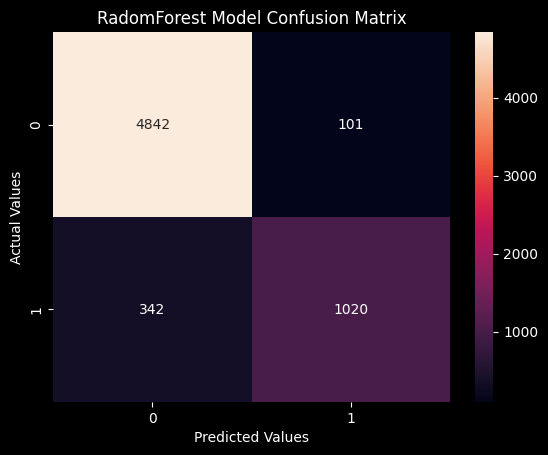

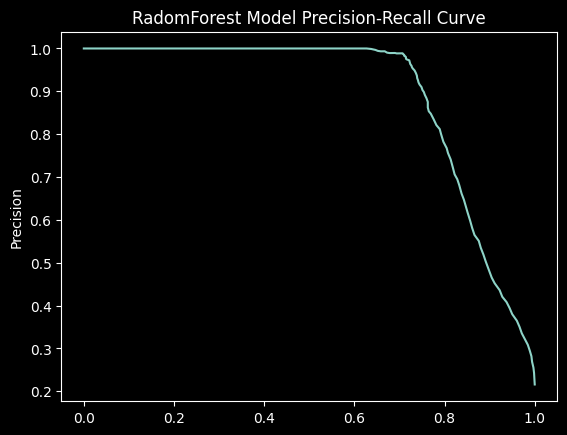

In [36]:
Evaluate_model("RadomForest Model",
               rf_model, X_test, y_test)

# ***8.0 - XGBoost model***

In [37]:
xg_model = Pipeline([
                    ('Preprocessor', preprocessor_xgboost),
                     ('classifier', XGBClassifier
                                  (scale_pos_weight = scale_weight,
                                  learning_rate = 0.1,
                                  random_state = 42))])

In [38]:
xg_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

XGBoost Model Metrics
Best Threshold None
Accuracy  : 0.92
Precision : 0.82
Recall    : 0.79
F1        : 0.81

XGBoost Model Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



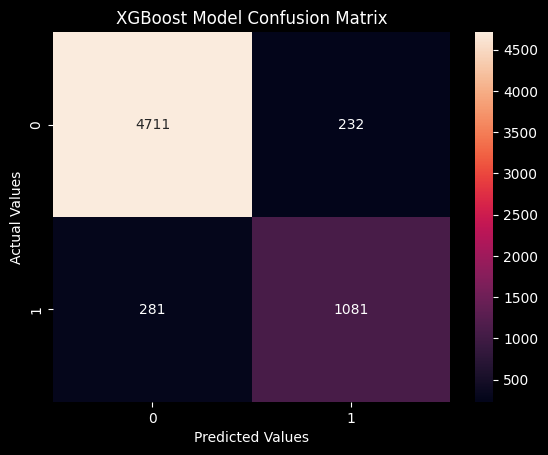

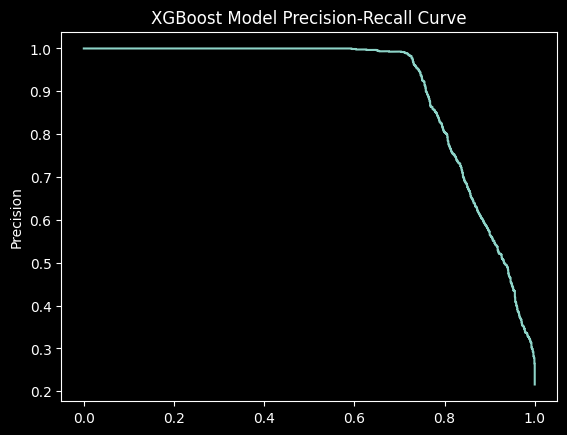

In [39]:
#valutating the XGboost model

Evaluate_model("XGBoost Model",
               xg_model, X_test, y_test)

# ***8.1 - Hyperparameter Tunning***

In [40]:
#Importing Libraries
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "classifier__n_estimatore"      : randint(150, 600),
    "classifier__max_depth"         : randint(3, 9),
    "classifier__learning_rate"     : uniform(0.01, 0.5),
    "classifier__subsample"         : uniform(0.6, 0.4),  #Row sampling
    "classifier__colsample_bytree"  : uniform(0.6, 0.4),  #Column sampling
    "classifier__min_child_weight"  : randint(1, 10),
    "classifier__gamma"             : randint(0, 5)
}

# ***8.2 - Model Training***

In [41]:
random_search = RandomizedSearchCV(
                                  xg_model,         #model name
                                  param_grid,
                                  n_iter  = 150,
                                  cv      = cv,
                                  scoring = "average_precision",
                                  n_jobs  = -1,
                                  verbose =  1)


random_search.fit(X_train, y_train)



Fitting 5 folds for each of 150 candidates, totalling 750 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': <scipy.stats....x7fe358ebfb10>, 'classifier__gamma': <scipy.stats....x7fe35d816060>, 'classifier__learning_rate': <scipy.stats....x7fe35db4b620>, 'classifier__max_depth': <scipy.stats....x7fe35db8f390>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",150
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index

In [42]:
print(f"Score after pefrom tunning:  {random_search.best_score_ * 100:.2f}")

Score after pefrom tunning:  90.09


In [43]:
#Best parameter after peforming HyperParameter tunning
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.8392536482485934),
 'classifier__gamma': 0,
 'classifier__learning_rate': np.float64(0.13808451484992457),
 'classifier__max_depth': 8,
 'classifier__min_child_weight': 9,
 'classifier__n_estimatore': 439,
 'classifier__subsample': np.float64(0.951872194088823)}

XGBoost Metrics
Best Threshold None
Accuracy  : 0.92
Precision : 0.84
Recall    : 0.80
F1        : 0.82

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      4943
           1       0.84      0.80      0.82      1362

    accuracy                           0.92      6305
   macro avg       0.89      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305



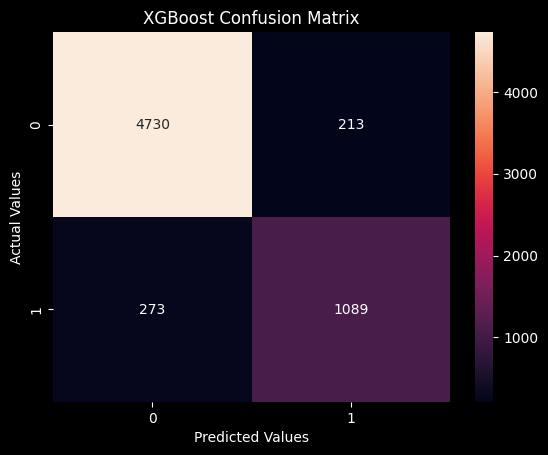

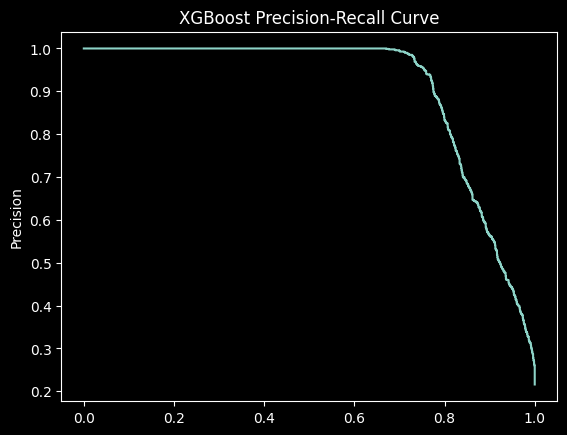

In [44]:
#Evaluating model
Evaluate_model("XGBoost", random_search,
               X_test, y_test)

# ***9.0 - Optimizing The classification Threshold***

XGBoost Metrics
Best Threshold 0.9996131062507629
Accuracy  : 0.78
Precision : 0.00
Recall    : 0.00
F1        : 0.00

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4943
           1       0.00      0.00      0.00      1362

    accuracy                           0.78      6305
   macro avg       0.39      0.50      0.44      6305
weighted avg       0.61      0.78      0.69      6305



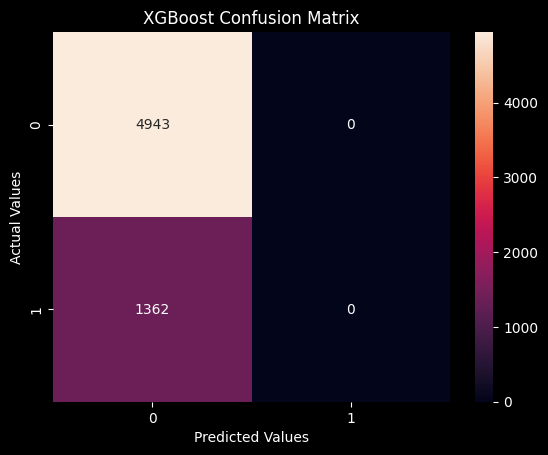

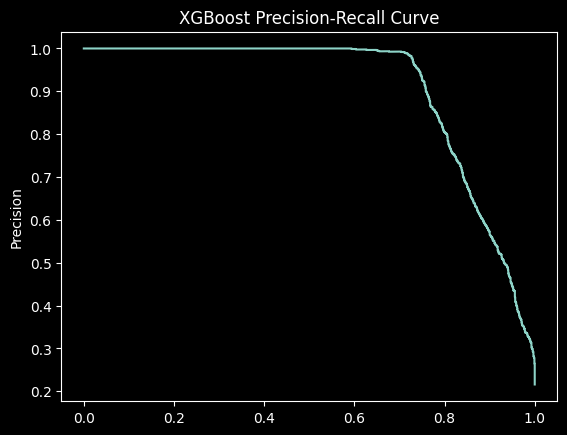

In [45]:
#importing Libraries.
from sklearn.metrics import precision_recall_curve

#get the probability of class 1 from the XGBoost.
prob = xg_model.predict_proba(X_test)[:, 1]
# prob

#For each threshold calculate precision and recall.
precisions, recalls, thresholds = precision_recall_curve(y_test, prob)

#Calculate f1 score.
f1_scores = 2 * (precisions - recalls) / (precisions + recalls + 1e-9)

#get the threshold that produce the higest score.
best_val = np.argmax(f1_scores[:-1])
best_thresholds_val = thresholds[best_val]

#Evaluate the XGboost model using threshold.
Evaluate_model("XGBoost", xg_model, X_test, y_test, best_thresholds_val)

# ***10.0 - Probability Calibration***

In [46]:
"""Methods by which we can fix the poorly calibrated model.
1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.
2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calilration)
3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature"""

'Methods by which we can fix the poorly calibrated model.\n1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.\n2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calilration)\n3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature'

In [47]:
#1. Calibrate XGBoost - model
#Importing Calibration model

from sklearn.calibration import CalibratedClassifierCV, calibration_curve

best_model = random_search.best_estimator_

calibrated_model = CalibratedClassifierCV(
                                          best_model,
                                          method='sigmoid',
                                          cv = 5
                                      )
calibrated_model.fit(X_train, y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2","Pipeline(step...=None, ...))])"
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn.cali...x7fe35d7c8980>, <

In [48]:
#2. Get probabilites
uncalibrated = xg_model.predict_proba(X_test)[:, 1]

calibrated = calibrated_model.predict_proba(X_test)[:, 1]

In [49]:
#3. create calibration curves
actual_uncal, prediction_uncal = calibration_curve(y_test,
                                                   uncalibrated,
                                                   n_bins = 10)

actual_cal, prediction_cal = calibration_curve(y_test,
                                              calibrated,
                                              n_bins = 10)

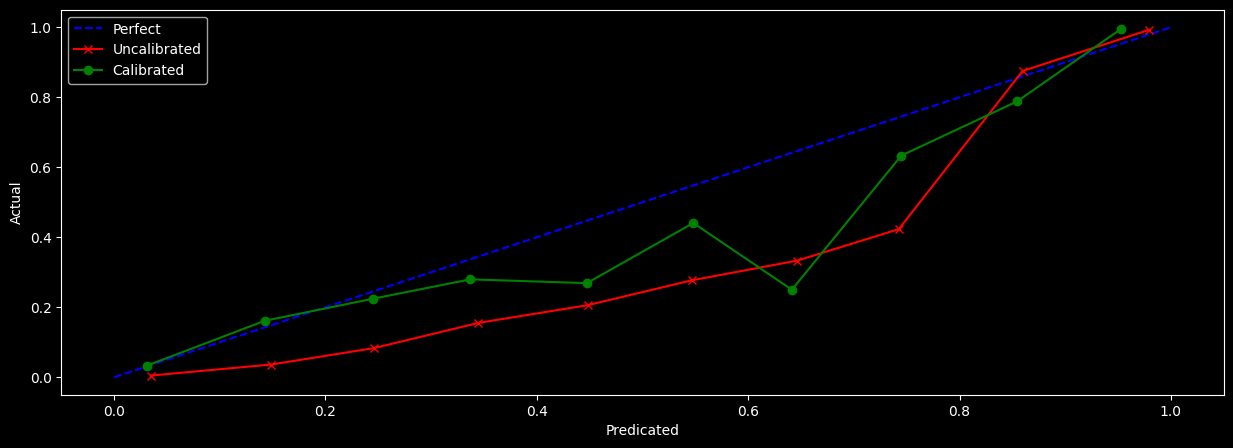

In [50]:
#4. plot
plt.figure(figsize=(15, 5))
plt.plot([0, 1], [0, 1], 'k--',
         label = "Perfect",
         color = "blue")

plt.plot(prediction_uncal,
         actual_uncal,
         'x-',
         label ="Uncalibrated",
         color='red')

plt.plot(prediction_cal,
         actual_cal,
         'o-',
         label ="Calibrated",
         color="green")

plt.xlabel("Predicated")
plt.ylabel("Actual")
plt.legend()
plt.show()

# ***11.0 SHAP Interpreation - Global & Logic***

In [51]:
"""
SHAP - shapley additive exPlaination : why a model maks a particular prediction?

1. shaps tells you how each feature contributed or Push the predections up or down and how much.

- Global SHAP: summarizes SHAP values for all data points to show which features influence the model the most overall.

                                      Base prediction      = 50%          ← Global / average model output
                                              │
                                      High CGPA            +20%
                                      Strong coding skill  +10%
                                      4 projects           +4%
                                      No backlogs          +2%
                                              │
                                      Final prediction     = 84%         ← Local prediction for this student

- Local SHAP: explains one individual prediction (one data point), such as why this student received an 84% prediction.
"""

'\nSHAP - shapley additive exPlaination : why a model maks a particular prediction?\n\n1. shaps tells you how each feature contributed or Push the predections up or down and how much.\n\n- Global SHAP: summarizes SHAP values for all data points to show which features influence the model the most overall.\n\n                                      Base prediction      = 50%          ← Global / average model output\n                                              │\n                                      High CGPA            +20%\n                                      Strong coding skill  +10%\n                                      4 projects           +4%\n                                      No backlogs          +2%\n                                              │\n                                      Final prediction     = 84%         ← Local prediction for this student\n\n- Local SHAP: explains one individual prediction (one data point), such as why this student received an 84% predicti

In [52]:
#Install shap

# !pip install shap

#1. Get the trained XGBoost classifier model  out of the pipeline
xgb_classifier = xg_model.named_steps['classifier']

In [53]:
#2. Transform X_test using the same preprocessor used for training
X_test_transformed = xg_model.named_steps['Preprocessor'].transform(X_test)

In [54]:
#3. Get the feature name after onehot encoding , so plot are readable
feature_names = xg_model.named_steps['Preprocessor'].get_feature_names_out()

In [55]:
#Convert to dataFrame for a clear shap plots.
X_test_df = pd.DataFrame(X_test_transformed,
                         columns = feature_names)

X_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,24.0,30000.0,1.0,15000.0,15.68,0.50,3.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,23.0,60000.0,6.0,25600.0,10.99,0.43,4.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,29.0,18000.0,2.0,3600.0,15.27,0.20,6.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,32.0,130000.0,7.0,13000.0,12.69,0.10,8.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,23.0,45288.0,7.0,20500.0,9.25,0.45,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6300,21.0,75000.0,5.0,20000.0,13.11,0.27,2.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6301,29.0,265000.0,2.0,25000.0,11.26,0.09,10.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6302,25.0,48996.0,8.0,5000.0,9.88,0.10,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6303,27.0,115000.0,11.0,8000.0,7.51,0.07,7.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [56]:
#Create SHAP explainer built for tree based model.
import shap

explainer = shap.TreeExplainer(xgb_classifier)

In [57]:
# calculate the shap value for for every row in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[-1.7525564e-01, -1.0555401e-01,  1.2984274e-01, ...,
        -7.3516299e-03, -3.8879909e-02,  0.0000000e+00],
       [ 4.7165085e-02, -8.7262326e-01, -9.4737314e-02, ...,
        -9.2151780e-03, -7.5508673e-03,  0.0000000e+00],
       [ 7.8027323e-02,  3.5025654e+00,  1.2711690e-01, ...,
        -7.3584518e-03,  7.7456667e-04,  0.0000000e+00],
       ...,
       [-8.6244913e-03,  5.8208084e-01,  7.2391242e-02, ...,
        -9.2837382e-03, -1.1459960e-02,  0.0000000e+00],
       [ 2.0838849e-02, -1.0313793e+00,  4.3692421e-02, ...,
        -9.2305308e-03, -1.1398584e-02,  0.0000000e+00],
       [-1.3665082e-01, -5.0866711e-01,  2.6854105e-02, ...,
        -8.8342456e-03, -1.0388625e-02,  0.0000000e+00]], dtype=float32)

# ***11.1 - Global Explaination***

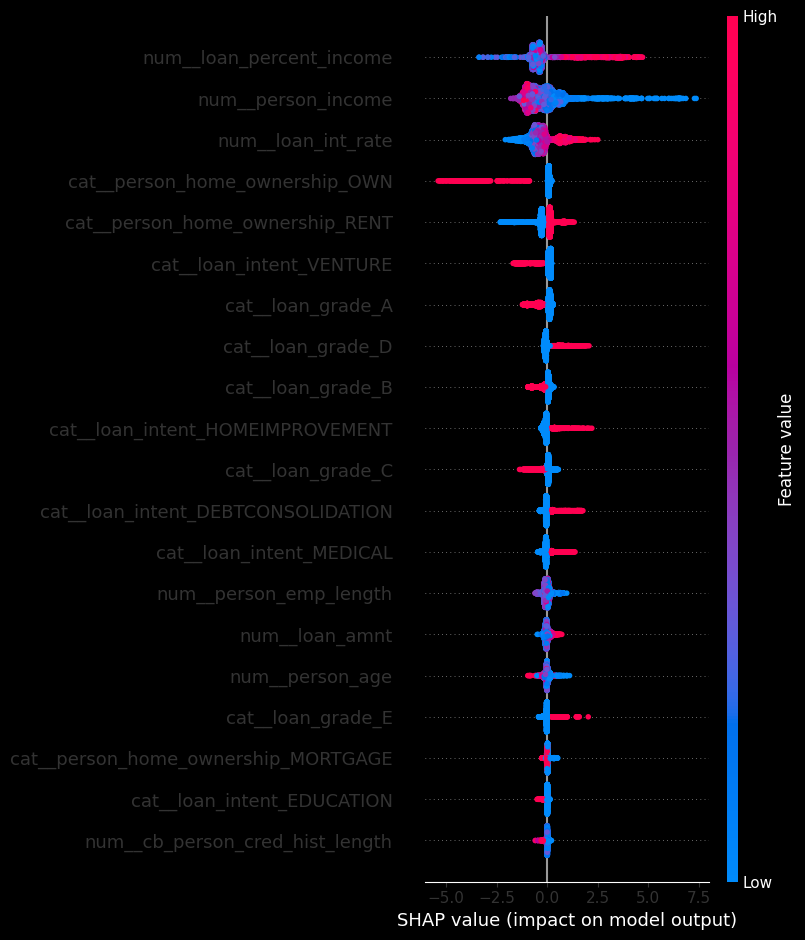

In [58]:
shap.summary_plot(shap_values, X_test_df)

# ***11.2 - Local Explaination***

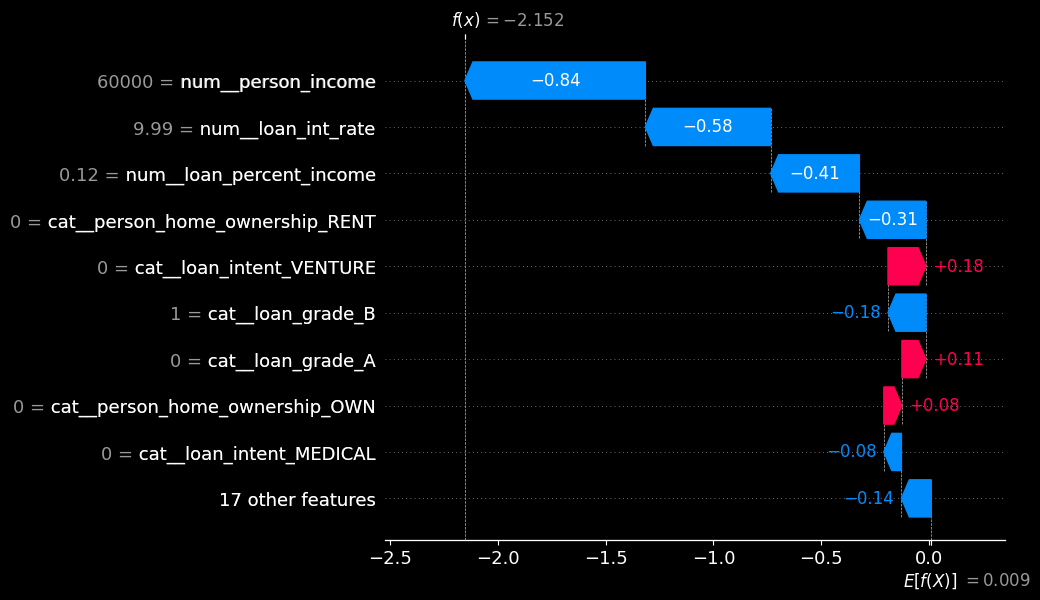

In [59]:
#Pick one row to explain, e.g. th applicant in the test set
row_index = 5

#2. Draw a waterfall chart showing how each feature pull the predection up and down.
shap.plots.waterfall(
                    shap.Explanation(
                        values = shap_values[row_index],        #Shap value at that particular index
                        base_values = explainer.expected_value,  #Predicated model value
                        data = X_test_df.iloc[row_index],
                        feature_names = feature_names
                    )
                )



# ***12.0 - Anlyzing False Positive & False Negative***

In [60]:
#Get predection from the best peforming XGBoost model on the test set.
y_pred = random_search.predict(X_test)

In [61]:
#Creat a DataFrame to compare Actual and Predicated value

result_df = X_test.copy()

result_df["actual"] = y_test
result_df["predicted"] = y_pred

In [62]:
result_df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,1
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0


In [63]:
#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual'] == 0) & (result_df['predicted' ] == 1) ]

#Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual'] == 1) & (result_df['predicted' ] == 0)]

In [64]:
print("False Positive :", len(false_positive))
print("False Negative :", len(false_negative))

False Positive : 213
False Negative : 273


# ***13.0 - Save The Model***

In [65]:
#Importing model
import joblib

In [66]:
joblib.dump(calibrated_model, "Credit_Risk_Model.pkl")

['Credit_Risk_Model.pkl']

# ***Calibrated Threshold***

In [67]:
from sklearn.metrics import precision_recall_curve
import numpy as np

calibrated_prob = calibrated_model.predict_proba(X_test)[:, 1]

#For each threshold calculate precision and recall.
precisions, recalls, thresholds = precision_recall_curve(y_test, calibrated_prob)

#Calculate f1 score.
f1_scores = 2 * (precisions - recalls) / (precisions + recalls + 1e-9)

#get the threshold that produce the higest score.
best_thresholds_val = thresholds[np.argmax(f1_scores[:-1])]

print("New thresholds",best_thresholds_val)

New thresholds 0.9576358277355608


In [68]:
joblib.dump(best_thresholds_val, "Best_Threshold.pkl")

['Best_Threshold.pkl']